# Segmentation crops
Pick crop regions from the candidates below (dense cortex tiles plus the pial region), then plot method rows and grids for the ones in `selected`. Output: `metrics/merged/plots/segmentation_crops/<region>/`.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import spatialdata as sd
from matplotlib import font_manager

sys.path.insert(0, str(Path.cwd().parents[0]))
from cellseg_benchmark import crop_plots as cp
from cellseg_benchmark._constants import BASE_PATH, main_methods, method_names

font_manager.fontManager.addfont(f"{BASE_PATH}/misc/Arial.ttf")
plt.rcParams.update({"font.family": "Arial", "svg.fonttype": "none"})
row_methods = ["Baysor_2D_denovo", "vpt_2D_DAPI_PolyT", "vpt_3D_DAPI_PolyT", "Proseg_3D_vpt3D_DAPI_nuclei"]
raw = {v: k for k, v in method_names.items()}
grid_methods = [raw[m] for m in pd.read_csv(Path(BASE_PATH) / "metrics/merged/benchmark_tables/all/combined.csv").method if m in main_methods]
out = Path(BASE_PATH) / "metrics/merged/plots/segmentation_crops"

/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


## Candidates
Section overview with the region in red, then 3D Cellpose and Baysor.

version mismatch: detected: RasterFormatV02, requested: FormatV04
/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/ubuntu/miniforge3/envs/seg_postp

INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                                                                   
INFO     Rasterizing image for faster rendering.                        

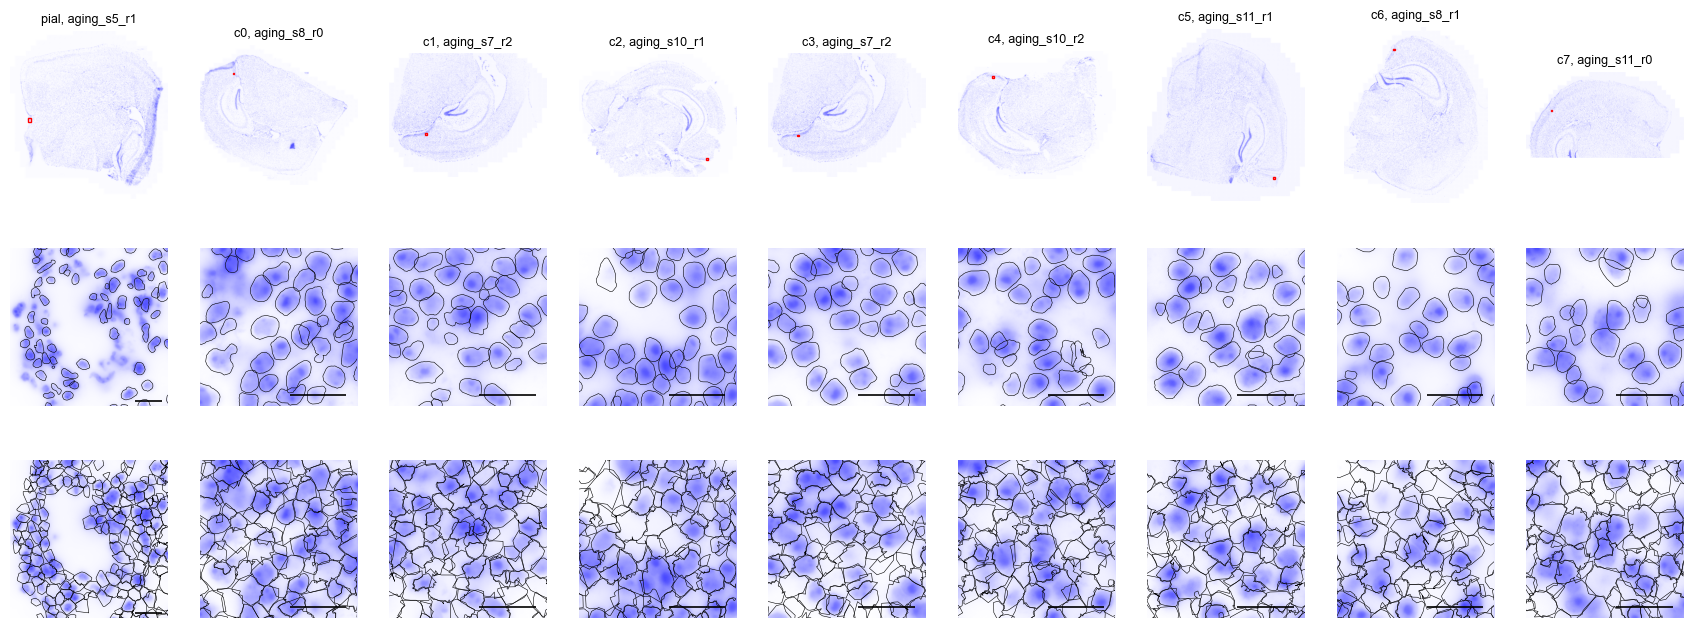

In [2]:
candidates = cp.find_candidates("aging", exclude=["aging_s5_r1"])
rois = {"pial": ("aging_s5_r1", (645, 3845, 145))} | {f"c{i}": (r["sample"], (r.x0, r.y0, 70)) for i, r in candidates.iterrows()}
sdatas = {s: sd.read_zarr(Path(BASE_PATH) / "samples" / s / "sdata_z3.zarr", selection=("images", "shapes")) for s, _ in rois.values()}
fig, axs = plt.subplots(3, len(rois), figsize=(2.4 * len(rois), 7.8))
for j, (name, (s, box)) in enumerate(rois.items()):
    sdatas[s].pl.render_images(f"{s}_z3", channel="DAPI", cmap=cp.dapi_cmap, colorbar=False).pl.show(coordinate_systems="micron", ax=axs[0, j], title="")
    axs[0, j].add_patch(plt.Rectangle(box[:2], box[2], box[2], fill=False, ec="red", lw=1))
    axs[0, j].axis("off")
    for ax, m in zip(axs[1:, j], ["vpt_3D_DAPI_PolyT", "Baysor_2D_denovo"]):
        cp.draw(ax, sdatas[s], s, m, box)
    axs[0, j].set_title(f"{name}, {s}", fontsize=9)

## Rows and grids

In [3]:
selected = ["c3", "c6", "pial"]
for name in selected:
    s, box = rois[name]
    (out / name).mkdir(parents=True, exist_ok=True)
    for qc in ("post", "both"):
        fig = cp.plot_row(sdatas[s], s, row_methods, box, "outlines", qc)
        for ext in ("png", "svg"):
            fig.savefig(out / name / f"row_{qc}qc.{ext}", dpi=600, bbox_inches="tight", pad_inches=0.02, transparent=True)
    for style in ("outlines", "celltypes", "transcripts"):
        fig = cp.plot_grid(sdatas[s], s, box, grid_methods, style, "both")
        for ext in ("png", "svg"):
            fig.savefig(out / name / f"grid_{style}.{ext}", dpi=600, transparent=True)
    plt.close("all")

/dss/dsshome1/0C/ra98gaq/git/cbm-panels/cellseg_benchmark/crop_plots.py:89: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  g[~kept].boundary.plot(ax=ax, aspect=None, color="0.5", lw=lw)
/dss/dsshome1/0C/ra98gaq/git/cbm-panels/cellseg_benchmark/crop_plots.py:89: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  g[~kept].boundary.plot(ax=ax, aspect=None, color="0.5", lw=lw)
/dss/dsshome1/0C/ra98gaq/git/cbm-panels/cellseg_benchmark/crop_plots.py:89: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  g[~kept].boundary.plot(ax=ax, aspect=None, color="0.5", lw=lw)
/dss/dsshome1/0C/ra98gaq/git/cbm-panels/cellseg_benchmark/crop_plots.py:89: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  g[~kept].boundary.plot(ax=ax, aspect=None, color="0.5", lw=lw)
/dss/dsshome1/0C/ra98gaq/git/cbm-panels/cellseg_benchmark/crop_plots

In [ ]:
out_sections = Path(BASE_PATH) / "metrics/merged/plots/section_overview"
out_sections.mkdir(parents=True, exist_ok=True)
for cohort in ["aging", "ABCAtlas", "VizgenMouseBrain"]:
    fig = cp.plot_sections(cohort)
    for ext in ("png", "svg"):
        fig.savefig(out_sections / f"{cohort}.{ext}", dpi=600, bbox_inches="tight", pad_inches=0.02, transparent=True)
    plt.close(fig)